Importing Libraries

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder

In [72]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##load dataset

In [73]:
filepath='/content/drive/MyDrive/dataset/Student_Depression_Dataset.csv'
student=pd.read_csv(filepath)

In [75]:
student.head(5)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [77]:
student.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   object 
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   object 
 3   Relationship_status  4464 non-null   object 
 4   Marital_status       4464 non-null   object 
 5   Living_style         4464 non-null   object 
 6   Current_semester     4464 non-null   int64  
 7   CGPA                 4464 non-null   float64
 8   friend_circle        4464 non-null   object 
 9   Health_condition     4464 non-null   object 
 10  Cost_without_study   4464 non-null   int64  
 11  Home_division        4464 non-null   object 
 12  Depression           4464 non-null   object 
dtypes: float64(1), int64(3), object(9)
memory usage: 453.5+ KB


In [74]:
student.describe()

,Age,Current_semester,CGPA,Cost_without_study
count,4464.000000,4464.000000,4464.000000,4464.000000
mean,22.619176,5.401210,3.412753,11242.978271
std,2.022980,2.578476,0.385605,6640.144019
min,17.000000,0.000000,2.250000,0.000000
25%,21.000000,3.000000,3.150000,6100.000000
50%,23.000000,5.000000,3.490000,9500.000000
75%,24.000000,7.000000,3.700000,15439.000000
max,28.000000,13.000000,4.000000,32000.000000


In [76]:
student.shape

(4464, 13)

#DATAFRAME - NUMERICAL & CATEGORICAL

1. Numerical
* Missing values
* Duplicates
* Standardization

2. Categorical
* Missing values
* Duplicates
* Encoding

##Splitting dataframe into categorical and numerical

In [78]:
num_cols=student.select_dtypes(include='number').columns
cat_cols=student.select_dtypes(include='object').columns
print(num_cols)
print(cat_cols)

Index(['Age', 'Current_semester', 'CGPA', 'Cost_without_study'], dtype='object')
Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition', 'Home_division',
       'Depression'],
      dtype='object')


##Checking missing values

In [79]:
student.isna().sum()

,0
Gender,0
Age,0
Family_background,0
Relationship_status,0
Marital_status,0
Living_style,0
Current_semester,0
CGPA,0
friend_circle,0
Health_condition,0


##Checking duplicate values

In [80]:
student.duplicated().sum()

np.int64(0)

##Outliers

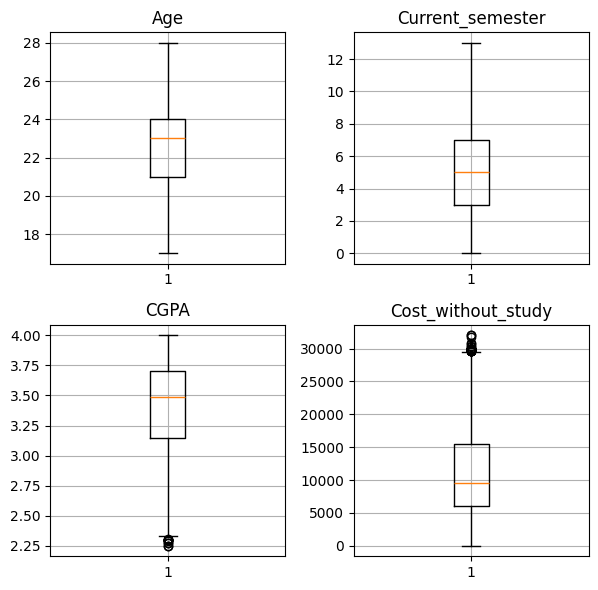

In [81]:
plt.figure(figsize=(6,6))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    plt.boxplot(student[col])
    plt.title(col)
    plt.grid()


plt.tight_layout()
plt.show()

##Outlier checking

In [100]:
Q1 = student[num_cols].quantile(0.25)
Q3 = student[num_cols].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = (
    (student[num_cols] < lower_limit) |
    (student[num_cols] > upper_limit)
)

print(outliers.sum())

Age                    0
Current_semester       0
CGPA                  12
Cost_without_study    36
dtype: int64


##Handling missing values

In [ ]:
student[num_cols].isna().sum()

In [ ]:
student[cat_cols].isna().sum()

##Label encoding

In [87]:
student['Depression'].unique()

array(['Yes', 'No'], dtype=object)

In [88]:
label_encoder=LabelEncoder()
student['Depression']=label_encoder.fit_transform(student['Depression'])
student['Depression'].unique()


array([1, 0])

In [89]:
student.head(5)

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,1
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,1
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,1
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,0
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,1


In [90]:
student['Health_condition'].unique()

array(['Critical', 'Abnormal', 'Good', 'Normal'], dtype=object)

##Ordinal encoding

In [91]:
encoder_health=OrdinalEncoder(
    categories=[['Normal','Good','Abnormal','Critical']]) #give our correct order

student['Health_condition']=encoder_health.fit_transform(student[['Health_condition']])
# Apply One-Hot Encoding to convert categorical health conditions into numerical values
print(student.head())

   Gender  Age Family_background Relationship_status Marital_status  \
0  Female   22      Middle class              Single      Unmarried   
1    Male   19      Middle class              Single      Unmarried   
2    Male   23      Middle class              Single      Unmarried   
3    Male   20      Middle class         Complicated      Unmarried   
4  Female   21      Middle class              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle  Health_condition  \
0     Bachelor                 8  3.43           Yes               3.0   
1     Bachelor                 2  3.70           Yes               2.0   
2       Family                 8  3.28            No               2.0   
3       Family                 2  3.77            No               1.0   
4       Family                 1  4.00            No               2.0   

   Cost_without_study Home_division  Depression  
0               10113    Chittagong           1  
1               13815    Chi

In [92]:
student['Family_background'].unique()
# Display all unique categories present in the Family_background column

array(['Middle class', 'Lower Middle class', 'Rich class'], dtype=object)

In [93]:
# Initialize OrdinalEncoder
encoder_family=OrdinalEncoder(
    categories=[['Lower Middle class','Middle class','Rich class']])
# Fit the encoder and transform categorical values into numerical values

student['Family_background']=encoder_family.fit_transform(student[['Family_background']])
print(student.head())

   Gender  Age  Family_background Relationship_status Marital_status  \
0  Female   22                1.0              Single      Unmarried   
1    Male   19                1.0              Single      Unmarried   
2    Male   23                1.0              Single      Unmarried   
3    Male   20                1.0         Complicated      Unmarried   
4  Female   21                1.0              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle  Health_condition  \
0     Bachelor                 8  3.43           Yes               3.0   
1     Bachelor                 2  3.70           Yes               2.0   
2       Family                 8  3.28            No               2.0   
3       Family                 2  3.77            No               1.0   
4       Family                 1  4.00            No               2.0   

   Cost_without_study Home_division  Depression  
0               10113    Chittagong           1  
1               13815 

##One hot encoding


In [94]:
# Initialize OneHotEncoder
encoder_gender = OneHotEncoder()

# Fit the encoder and transform Gender categorical values
encoded_data = encoder_gender.fit_transform(student[['Gender']])

# Convert the encoded array into a DataFrame with column names and original index
encoded_df = pd.DataFrame(
    encoded_data.toarray(), #Convert sparse encoded data into a dense NumPy array
    columns=encoder_gender.get_feature_names_out(['Gender']), #Get column names for each encoded category
    index=student.index #Maintain the original DataFrame index
)

#Combine the encoded columns with the remaining student DataFrame
student=pd.concat([encoded_df,student.drop('Gender',axis=1)],axis=1)
student.head()

,Gender_Female,Gender_Male,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,1.0,0.0,22,1.0,Single,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,0.0,1.0,19,1.0,Single,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,0.0,1.0,23,1.0,Single,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1
3,0.0,1.0,20,1.0,Complicated,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0
4,1.0,0.0,21,1.0,Single,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1


In [95]:
encoder_relationship = OneHotEncoder()

encoded_data = encoder_relationship.fit_transform(student[['Relationship_status']])

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_relationship.get_feature_names_out(['Relationship_status']),
    index=student.index
)



student = pd.concat([encoded_df, student.drop('Relationship_status', axis=1)], axis=1)
student.head()

,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Gender_Female,Gender_Male,Age,Family_background,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0.0,0.0,1.0,1.0,0.0,22,1.0,Unmarried,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,0.0,0.0,1.0,0.0,1.0,19,1.0,Unmarried,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,0.0,0.0,1.0,0.0,1.0,23,1.0,Unmarried,Family,8,3.28,No,2.0,15450,Dhaka,1
3,1.0,0.0,0.0,0.0,1.0,20,1.0,Unmarried,Family,2,3.77,No,1.0,17413,Dhaka,0
4,0.0,0.0,1.0,1.0,0.0,21,1.0,Unmarried,Family,1,4.00,No,2.0,16693,Dhaka,1


In [96]:
encoder_marital = OneHotEncoder()

encoded_data = encoder_marital.fit_transform(student[['Marital_status']])

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_marital.get_feature_names_out(['Marital_status']),
    index=student.index
)



student = pd.concat([encoded_df, student.drop('Marital_status', axis=1)], axis=1)
student.head()

,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Gender_Female,Gender_Male,Age,Family_background,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,22,1.0,Bachelor,8,3.43,Yes,3.0,10113,Chittagong,1
1,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,19,1.0,Bachelor,2,3.70,Yes,2.0,13815,Chittagong,1
2,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,23,1.0,Family,8,3.28,No,2.0,15450,Dhaka,1
3,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,20,1.0,Family,2,3.77,No,1.0,17413,Dhaka,0
4,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,21,1.0,Family,1,4.00,No,2.0,16693,Dhaka,1


In [97]:
encoder_living = OneHotEncoder()

encoded_data = encoder_living.fit_transform(student[['Living_style']])

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_living.get_feature_names_out(['Living_style']),
    index=student.index
)



student = pd.concat([encoded_df, student.drop('Living_style', axis=1)], axis=1)
student.head()

,Living_style_Bachelor,Living_style_Family,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Gender_Female,Gender_Male,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,22,1.0,8,3.43,Yes,3.0,10113,Chittagong,1
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,19,1.0,2,3.70,Yes,2.0,13815,Chittagong,1
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,23,1.0,8,3.28,No,2.0,15450,Dhaka,1
3,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,20,1.0,2,3.77,No,1.0,17413,Dhaka,0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,21,1.0,1,4.00,No,2.0,16693,Dhaka,1


In [98]:
encoder_friend = LabelEncoder()

student['friend_circle'] = encoder_friend.fit_transform(student['friend_circle'])

student.head()

,Living_style_Bachelor,Living_style_Family,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Gender_Female,Gender_Male,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,22,1.0,8,3.43,1,3.0,10113,Chittagong,1
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,19,1.0,2,3.70,1,2.0,13815,Chittagong,1
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,23,1.0,8,3.28,0,2.0,15450,Dhaka,1
3,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,20,1.0,2,3.77,0,1.0,17413,Dhaka,0
4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,21,1.0,1,4.00,0,2.0,16693,Dhaka,1


In [99]:
encoder_home = OneHotEncoder()

encoded_data = encoder_home.fit_transform(student[['Home_division']])

encoded_df = pd.DataFrame(
    encoded_data.toarray(),
    columns=encoder_home.get_feature_names_out(['Home_division']),
    index=student.index
)



student = pd.concat([encoded_df, student.drop('Home_division', axis=1)], axis=1)
student.head()

,Home_division_Barisal,Home_division_Chittagong,Home_division_Dhaka,Home_division_Khulna,Home_division_Mymensingh,Home_division_Rajshahi,Home_division_Rangpur,Home_division_Sylhet,Living_style_Bachelor,Living_style_Family,...,Gender_Female,Gender_Male,Age,Family_background,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Depression
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,22,1.0,8,3.43,1,3.0,10113,1
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,19,1.0,2,3.70,1,2.0,13815,1
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,23,1.0,8,3.28,0,2.0,15450,1
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,20,1.0,2,3.77,0,1.0,17413,0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,21,1.0,1,4.00,0,2.0,16693,1


##Train test split

In [82]:
X = student.drop('Depression', axis=1)

y = student['Depression']

In [83]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

##Standardization

In [84]:
num_cols = ['Age', 'Current_semester', 'CGPA', 'Cost_without_study']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])


In [ ]:
X_train.head()